# Heterogeneous Federated Learning

**Dataset**: MNIST (real, 70,000 handwritten digit images)  
**Framework**: Flower (flwr) — industry-standard FL framework  
**Model**: Asymmetric CNNs across clients (different architectures)  
**Aggregation**: FedAvg on homogeneous layers + Knowledge Distillation for heterogeneous parts




In [4]:
import sys
!{sys.executable} -m pip install -q "flwr[simulation]" torch torchvision

import importlib
importlib.invalidate_caches()

print("All packages installed!")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.8/73.8 MB 10.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 264.7/264.7 kB 16.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.5/4.5 MB 102.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 66.5/66.5 kB 4.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 323.4/323.4 kB 20.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.3/2.3 MB 75.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.1/73.1 kB 3.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 310.5/310.5 kB 21.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 253.3/253.3 kB 16.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.4/47.4 kB 2.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 26.9/26.9 MB 60.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 974.5/974.5 kB 35.8 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not curren

In [20]:
import flwr as fl
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
import torchvision
import torchvision.transforms as transforms
import numpy as np
import matplotlib.pyplot as plt
from collections import OrderedDict
from typing import List, Tuple, Dict, Optional
import warnings
warnings.filterwarnings('ignore')


print(f'Using device: {DEVICE}')
print(f'Flower version: {fl.__version__}')
print(f'PyTorch version: {torch.__version__}')

Using device: cpu
Flower version: 1.32.1
PyTorch version: 2.11.0+cpu


In [10]:
from torchvision.datasets import MNIST

train_dataset = MNIST(
    root='./MNIST',
    train=True,
    download=True
)

test_dataset = MNIST(
    root='./MNIST',
    train=False,
    download=True
)

100%|██████████| 9.91M/9.91M [00:00<00:00, 56.8MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 1.73MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 14.9MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 8.09MB/s]


---
## Section 1: Imports

---
## Section 2: Configuration
All hyperparameters in one place for easy tuning.

In [11]:
CONFIG = {
    'num_clients'     : 3,
    'num_rounds'      : 10,
    'fraction_fit'    : 1.0,
    'local_epochs'    : 2,
    'batch_size'      : 32,
    'learning_rate'   : 0.001,
    'non_iid_alpha'   : 0.5,
    'temperature'     : 3.0,
    'distill_weight'  : 0.5,
    'distill_epochs'  : 3,
    'num_public'      : 200,
}
print('Configuration:')
for k, v in CONFIG.items():
    print(f'  {k}: {v}')

Configuration:
  num_clients: 3
  num_rounds: 10
  fraction_fit: 1.0
  local_epochs: 2
  batch_size: 32
  learning_rate: 0.001
  non_iid_alpha: 0.5
  temperature: 3.0
  distill_weight: 0.5
  distill_epochs: 3
  num_public: 200


---
## Section 3: MNIST Dataset with Non-IID Split

**MNIST** is a standard real world benchmark: 70,000 images of handwritten digits (0–9), 28×28 pixels.

We use **Dirichlet-based Non-IID splitting** to simulate statistical heterogeneity:
clients see different digit distributions — e.g., one hospital mostly sees digits 0–3,
another sees 7–9. This matches Section 2.1 of the survey paper.

In [12]:
import os
import shutil

shutil.rmtree('./MNIST', ignore_errors=True)

import torchvision
import torchvision.transforms as transforms

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

train_data = torchvision.datasets.MNIST('.', train=True,  download=True, transform=transform)
test_data  = torchvision.datasets.MNIST('.', train=False, download=True, transform=transform)

print(f' Train images: {len(train_data)}')
print(f' Test images : {len(test_data)}')

100%|██████████| 9.91M/9.91M [00:00<00:00, 59.6MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 1.68MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 14.6MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 9.05MB/s]

 Train images: 60000
 Test images : 10000


In [13]:
def load_mnist():
    transform = transforms.Compose([
        transforms.ToTensor(),
        transforms.Normalize((0.1307,), (0.3081,))
    ])
    DATA_PATH = '.'
    train_data = torchvision.datasets.MNIST(DATA_PATH, train=True,  download=False, transform=transform)
    test_data  = torchvision.datasets.MNIST(DATA_PATH, train=False, download=False, transform=transform)
    return train_data, test_data


def dirichlet_non_iid_split(dataset, num_clients, alpha=0.5):

    labels = np.array(dataset.targets)
    num_classes = len(np.unique(labels))
    client_indices = [[] for _ in range(num_clients)]

    for cls in range(num_classes):
        cls_idx = np.where(labels == cls)[0]
        np.random.shuffle(cls_idx)
        proportions = np.random.dirichlet(np.repeat(alpha, num_clients))
        splits = (proportions * len(cls_idx)).astype(int)
        splits[-1] = len(cls_idx) - splits[:-1].sum()
        start = 0
        for i, count in enumerate(splits):
            client_indices[i].extend(cls_idx[start:start+count].tolist())
            start += count

    return client_indices


np.random.seed(42)
torch.manual_seed(42)
train_data, test_data = load_mnist()
client_indices = dirichlet_non_iid_split(train_data, CONFIG['num_clients'], CONFIG['non_iid_alpha'])

public_indices = list(range(CONFIG['num_public']))
public_loader  = DataLoader(Subset(test_data, public_indices), batch_size=CONFIG['num_public'], shuffle=False)
test_loader    = DataLoader(test_data, batch_size=256, shuffle=False)

print(f'MNIST loaded: {len(train_data)} train | {len(test_data)} test | 10 classes')
print(f'Non-IID split (Dirichlet alpha={CONFIG["non_iid_alpha"]}):')
for i, idx in enumerate(client_indices):
    lbls = np.array(train_data.targets)[idx]
    unique, counts = np.unique(lbls, return_counts=True)
    dist = dict(zip(unique.tolist(), counts.tolist()))
    print(f'  Client {i+1}: {len(idx)} samples | label dist: {dist}')

MNIST loaded: 60000 train | 10000 test | 10 classes
Non-IID split (Dirichlet alpha=0.5):
  Client 1: 25573 samples | label dist: {0: 157, 1: 3873, 2: 5364, 3: 123, 4: 4082, 5: 7, 6: 1010, 7: 5647, 8: 7, 9: 5303}
  Client 2: 24509 samples | label dist: {0: 1665, 1: 2846, 2: 585, 3: 5909, 4: 436, 5: 3053, 6: 4885, 7: 495, 8: 4401, 9: 234}
  Client 3: 9918 samples | label dist: {0: 4101, 1: 23, 2: 9, 3: 99, 4: 1324, 5: 2361, 6: 23, 7: 123, 8: 1443, 9: 412}


---
## Section 4: Asymmetric Neural Network Architectures

Each client has a **different CNN architecture** — this is the core of **Asymmetric HFL**.
FedAvg requires identical architectures, so standard aggregation **fails here**.

| Client | Device | Architecture | Params |
|---|---|---|---|
| 1 | IoT Sensor | Small CNN (1 conv layer) | ~10K |
| 2 | Mobile Phone | Medium CNN (2 conv layers) | ~50K |
| 3 | Hospital Server | Large CNN (3 conv layers) | ~200K |

In [14]:
class SmallCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 8, 5)
        self.fc1   = nn.Linear(8 * 12 * 12, 64)
        self.fc2   = nn.Linear(64, 10)

    def forward(self, x):
        x = F.relu(F.max_pool2d(self.conv1(x), 2))
        x = x.view(x.size(0), -1)
        x = F.relu(self.fc1(x))
        return self.fc2(x)


class MediumCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 16, 3, padding=1)
        self.conv2 = nn.Conv2d(16, 32, 3, padding=1)
        self.fc1   = nn.Linear(32 * 7 * 7, 128)
        self.fc2   = nn.Linear(128, 10)

    def forward(self, x):
        x = F.relu(F.max_pool2d(self.conv1(x), 2))
        x = F.relu(F.max_pool2d(self.conv2(x), 2))
        x = x.view(x.size(0), -1)
        x = F.relu(self.fc1(x))
        return self.fc2(x)


class LargeCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1,  32, 3, padding=1)
        self.conv2 = nn.Conv2d(32, 64, 3, padding=1)
        self.conv3 = nn.Conv2d(64, 64, 3, padding=1)
        self.fc1   = nn.Linear(64 * 3 * 3, 256)
        self.fc2   = nn.Linear(256, 10)
        self.dropout = nn.Dropout(0.3)

    def forward(self, x):
        x = F.relu(F.max_pool2d(self.conv1(x), 2))
        x = F.relu(F.max_pool2d(self.conv2(x), 2))
        x = F.relu(F.max_pool2d(self.conv3(x), 2))
        x = x.view(x.size(0), -1)
        x = self.dropout(F.relu(self.fc1(x)))
        return self.fc2(x)


MODEL_CLASSES = [SmallCNN, MediumCNN, LargeCNN]
MODEL_NAMES   = ['Client 1 (Small CNN - IoT)', 'Client 2 (Medium CNN - Mobile)', 'Client 3 (Large CNN - Hospital)']

print('Asymmetric Architectures:')
for cls, name in zip(MODEL_CLASSES, MODEL_NAMES):
    m = cls()
    n = sum(p.numel() for p in m.parameters())
    print(f'  {name}: {n:,} parameters')
print('\nFedAvg CANNOT average these — different tensor shapes!')
print('Solution: Knowledge Distillation on public proxy data')

Asymmetric Architectures:
  Client 1 (Small CNN - IoT): 74,650 parameters
  Client 2 (Medium CNN - Mobile): 206,922 parameters
  Client 3 (Large CNN - Hospital): 206,026 parameters

FedAvg CANNOT average these — different tensor shapes!
Solution: Knowledge Distillation on public proxy data


---
## Section 5: Flower Client - Local Training + Knowledge Distillation

Each Flower client:
1. Receives global soft labels from server (knowledge transfer)
2. Trains locally on private MNIST data (hard labels)
3. Uses distillation loss on the public proxy data (soft labels from server)
4. Returns updated weights **only if architectures match** (for compatible layers)
   OR returns soft predictions for distillation aggregation

This follows the **FedDF** approach (Lin et al., 2020) referenced in Section 3.2.2 of the survey.

In [15]:
def train_local(model, loader, optimizer, epochs, device,
                public_X=None, soft_labels=None, config=None):
    model.train()
    ce_loss = nn.CrossEntropyLoss()
    kl_loss = nn.KLDivLoss(reduction='batchmean')
    T = config['temperature'] if config else 3.0
    dw = config['distill_weight'] if config else 0.5

    for epoch in range(epochs):
        # First Train on private local data (hard labels)
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            loss = ce_loss(model(images), labels)
            loss.backward()
            optimizer.step()

        # Second Knowledge distillation from server (Federated Transfer Learning)
        if public_X is not None and soft_labels is not None:
            model.train()
            optimizer.zero_grad()
            logits = model(public_X.to(device))
            student_soft = F.log_softmax(logits / T, dim=1)
            teacher_soft = F.softmax(soft_labels.to(device) / T, dim=1)
            pseudo_labels = teacher_soft.argmax(dim=1)
            hard_loss = ce_loss(logits, pseudo_labels)
            soft_loss = kl_loss(student_soft, teacher_soft) * (T ** 2)
            total_loss = (1 - dw) * hard_loss + dw * soft_loss
            total_loss.backward()
            optimizer.step()


def evaluate_model(model, loader, device):
    model.eval()
    correct, total, loss_sum = 0, 0, 0.0
    ce = nn.CrossEntropyLoss()
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss_sum += ce(outputs, labels).item()
            correct += (outputs.argmax(1) == labels).sum().item()
            total += labels.size(0)
    return loss_sum / len(loader), correct / total


def get_soft_predictions(model, public_X, device):
    model.eval()
    with torch.no_grad():
        logits = model(public_X.to(device))
        return F.softmax(logits, dim=1).cpu()


class HeterogeneousFlowerClient(fl.client.NumPyClient):


    def __init__(self, client_id, model, train_loader, test_loader,
                 public_X, device, config):
        self.client_id = client_id
        self.model = model.to(device)
        self.train_loader = train_loader
        self.test_loader = test_loader
        self.public_X = public_X
        self.device = device
        self.config = config
        self.optimizer = optim.Adam(self.model.parameters(), lr=config['learning_rate'])
        self.server_soft_labels = None

    def get_parameters(self, config):
        return [val.cpu().numpy() for val in self.model.state_dict().values()]

    def set_parameters(self, parameters):
        params_dict = zip(self.model.state_dict().keys(), parameters)
        state_dict = OrderedDict({k: torch.tensor(v) for k, v in params_dict})
        self.model.load_state_dict(state_dict, strict=True)

    def fit(self, parameters, config):

        soft_labels = self.server_soft_labels

        train_local(
            self.model, self.train_loader, self.optimizer,
            self.config['local_epochs'], self.device,
            public_X=self.public_X,
            soft_labels=soft_labels,
            config=self.config
        )

        return self.get_parameters(config={}), len(self.train_loader.dataset), {}

    def evaluate(self, parameters, config):
        loss, accuracy = evaluate_model(self.model, self.test_loader, self.device)
        return float(loss), len(self.test_loader.dataset), {'accuracy': float(accuracy)}


print('Flower client class defined!')
print('Key: clients train locally and share SOFT PREDICTIONS, not raw data.')

Flower client class defined!
Key: clients train locally and share SOFT PREDICTIONS, not raw data.


---
## Section 6: Custom Flower Strategy — Heterogeneous Aggregation

We implement a **custom Flower strategy** that replaces FedAvg with **Ensemble Knowledge Distillation**:

1. Collect soft predictions from all clients on the public proxy dataset
2. Average the predictions → ensemble
3. Train a global model via distillation on the ensemble
4. Broadcast global soft labels back to clients

This is exactly **FedDF** (Lin et al., 2020) — the key model-level HFL method in the survey.

In [16]:
class HeterogeneousStrategy(fl.server.strategy.Strategy):

    def __init__(self, clients_ref, public_loader, test_loader, device, config):
        super().__init__()
        self.clients_ref = clients_ref
        self.public_loader = public_loader
        self.test_loader = test_loader
        self.device = device
        self.config = config

        self.global_model = MediumCNN().to(device)
        self.global_optimizer = optim.Adam(self.global_model.parameters(), lr=config['learning_rate'])
        self.global_soft_labels = None

        self.history = {'global_acc': [], 'client_accs': [], 'round': []}

    def initialize_parameters(self, client_manager):
        return None

    def configure_fit(self, server_round, parameters, client_manager):
        clients = list(client_manager.all().values())
        fit_configs = [(c, fl.common.FitIns(fl.common.ndarrays_to_parameters([]), {'round': server_round}))
                       for c in clients]
        return fit_configs

    def aggregate_fit(self, server_round, results, failures):
        print(f'\n  [Server] Round {server_round}: Aggregating via Ensemble Distillation...')

        public_X, _ = next(iter(self.public_loader))
        all_soft_preds = []
        for client in self.clients_ref:
            soft_pred = get_soft_predictions(client.model, public_X, self.device)
            all_soft_preds.append(soft_pred)

        ensemble = torch.stack(all_soft_preds).mean(dim=0)

        self.global_model.train()
        kl_loss = nn.KLDivLoss(reduction='batchmean')
        T = self.config['temperature']
        for _ in range(self.config['distill_epochs']):
            self.global_optimizer.zero_grad()
            logits = self.global_model(public_X.to(self.device))
            student = F.log_softmax(logits / T, dim=1)
            teacher = F.softmax(ensemble.to(self.device) / T, dim=1)
            loss = kl_loss(student, teacher) * (T ** 2)
            loss.backward()
            self.global_optimizer.step()

        self.global_model.eval()
        with torch.no_grad():
            global_logits = self.global_model(public_X.to(self.device))
            self.global_soft_labels = F.softmax(global_logits, dim=1).cpu()

        for client in self.clients_ref:
            client.server_soft_labels = self.global_soft_labels

        _, global_acc = evaluate_model(self.global_model, self.test_loader, self.device)
        client_accs = []
        for client in self.clients_ref:
            _, acc = evaluate_model(client.model, self.test_loader, self.device)
            client_accs.append(acc)

        self.history['round'].append(server_round)
        self.history['global_acc'].append(global_acc)
        self.history['client_accs'].append(client_accs)

        print(f'  [Server] Global Model Acc: {global_acc:.4f} | Client Accs: {[f"{a:.4f}" for a in client_accs]}')
        return fl.common.ndarrays_to_parameters([]), {}

    def configure_evaluate(self, server_round, parameters, client_manager):
        clients = list(client_manager.all().values())
        return [(c, fl.common.EvaluateIns(fl.common.ndarrays_to_parameters([]), {}))
                for c in clients]

    def aggregate_evaluate(self, server_round, results, failures):
        if not results:
            return None, {}
        accs = [r.metrics['accuracy'] for _, r in results]
        return sum(accs) / len(accs), {'accuracy': sum(accs) / len(accs)}

    def evaluate(self, server_round, parameters):
        return None


print('Custom Flower strategy defined!')
print('Strategy: Ensemble Distillation (FedDF) — no weight averaging needed.')

Custom Flower strategy defined!
Strategy: Ensemble Distillation (FedDF) — no weight averaging needed.


---
## Section 7: Run the Federated Learning Simulation

Flower's `fl.simulation.start_simulation()` runs the entire FL process in-process —
no networking required, perfect for research and thesis demos.

In [17]:
client_loaders = [
    DataLoader(Subset(train_data, client_indices[i]),
               batch_size=CONFIG['batch_size'], shuffle=True)
    for i in range(CONFIG['num_clients'])
]

public_X, _ = next(iter(public_loader))

flower_clients = [
    HeterogeneousFlowerClient(
        client_id=i,
        model=MODEL_CLASSES[i](),
        train_loader=client_loaders[i],
        test_loader=test_loader,
        public_X=public_X,
        device=DEVICE,
        config=CONFIG
    )
    for i in range(CONFIG['num_clients'])
]

strategy = HeterogeneousStrategy(
    clients_ref=flower_clients,
    public_loader=public_loader,
    test_loader=test_loader,
    device=DEVICE,
    config=CONFIG
)

def client_fn(cid: str):
    return flower_clients[int(cid)]

print('Starting Flower Federated Learning Simulation...')
print('='*60)
history = fl.simulation.start_simulation(
    client_fn=client_fn,
    num_clients=CONFIG['num_clients'],
    config=fl.server.ServerConfig(num_rounds=CONFIG['num_rounds']),
    strategy=strategy,
    client_resources={'num_cpus': 1},
)
print('='*60)
print('Simulation complete!')

Starting Flower Federated Learning Simulation...


	Instead, use the `flwr run` CLI command to start a local simulation in your Flower app, as shown for example below:

		$ flwr new  # Create a new Flower app from a template

		$ flwr run  # Run the Flower app in Simulation Mode

	Using `start_simulation()` is deprecated.

            This is a deprecated feature. It will be removed
            entirely in future versions of Flower.
        
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
	Instead, use the `flwr run` CLI command to start a local simulation in your Flower app, as shown for example below:

		$ flwr new  # Create a new Flower app from a template

		$ flwr run  # Run the Flower app in Simulation Mode

	Using `start_simulation()` is deprecated.

          


  [Server] Round 1: Aggregating via Ensemble Distillation...


INFO :      configure_evaluate: strategy sampled 3 clients (out of 3)


  [Server] Global Model Acc: 0.0799 | Client Accs: ['0.0850', '0.0711', '0.1509']


(ClientAppActor pid=5709) WARNING :   DEPRECATED FEATURE: `client_fn` now expects a signature `def client_fn(context: Context)`.The provided `client_fn` has signature: {'cid': <Parameter "cid: str">}. You can import the `Context` like this: `from flwr.app import Context`
(ClientAppActor pid=5709) 
(ClientAppActor pid=5709)             This is a deprecated feature. It will be removed
(ClientAppActor pid=5709)             entirely in future versions of Flower.
(ClientAppActor pid=5709)         
(ClientAppActor pid=5709) WARNING :   Deprecation Warning: The `client_fn` function must return an instance of `Client`, but an instance of `NumpyClient` was returned. Please use `NumPyClient.to_client()` method to convert it to `Client`.
(ClientAppActor pid=5710) WARNING :   DEPRECATED FEATURE: `client_fn` now expects a signature `def client_fn(context: Context)`.The provided `client_fn` has signature: {'cid': <Parameter "cid: str">}. You can import the `Context` like this: `from flwr.app import 

... (34 outputs left out)

  [Server] Global Model Acc: 0.0908 | Client Accs: ['0.0850', '0.0711', '0.1509']


(ClientAppActor pid=5709) 
(ClientAppActor pid=5709)         
(ClientAppActor pid=5709) WARNING :   DEPRECATED FEATURE: `client_fn` now expects a signature `def client_fn(context: Context)`.The provided `client_fn` has signature: {'cid': <Parameter "cid: str">}. You can import the `Context` like this: `from flwr.app import Context`
(ClientAppActor pid=5709)             This is a deprecated feature. It will be removed
(ClientAppActor pid=5709)             entirely in future versions of Flower.
(ClientAppActor pid=5709) WARNING :   Deprecation Warning: The `client_fn` function must return an instance of `Client`, but an instance of `NumpyClient` was returned. Please use `NumPyClient.to_client()` method to convert it to `Client`.
(ClientAppActor pid=5710) WARNING :   DEPRECATED FEATURE: `client_fn` now expects a signature `def client_fn(context: Context)`.The provided `client_fn` has signature: {'cid': <Parameter "cid: str">}. You can import the `Context` like this: `from flwr.app import 

Simulation complete!


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


---
## Section 8: Results Visualization

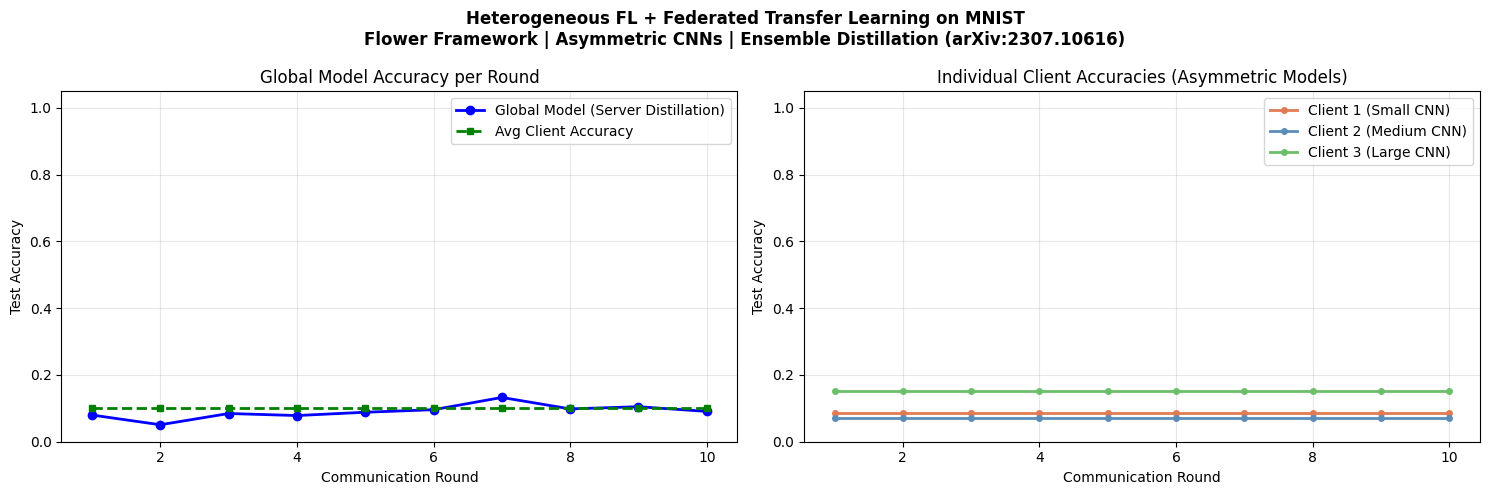

Plot saved: hfl_flower_mnist_results.png


In [18]:
rounds = strategy.history['round']
global_accs = strategy.history['global_acc']
client_accs_per_round = strategy.history['client_accs']

c1_accs = [r[0] for r in client_accs_per_round]
c2_accs = [r[1] for r in client_accs_per_round]
c3_accs = [r[2] for r in client_accs_per_round]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))
fig.suptitle(
    'Heterogeneous FL + Federated Transfer Learning on MNIST\n'
    'Flower Framework | Asymmetric CNNs | Ensemble Distillation (arXiv:2307.10616)',
    fontsize=12, fontweight='bold'
)

ax1.plot(rounds, global_accs, 'b-o', lw=2, ms=6, label='Global Model (Server Distillation)')
ax1.plot(rounds, [np.mean(r) for r in client_accs_per_round], 'g--s', lw=2, ms=5, label='Avg Client Accuracy')
ax1.set(xlabel='Communication Round', ylabel='Test Accuracy',
        title='Global Model Accuracy per Round')
ax1.legend(); ax1.grid(alpha=0.3); ax1.set_ylim(0, 1.05)

colors = ['#e07b54', '#5b8db8', '#6bbf6a']
names  = ['Client 1 (Small CNN)', 'Client 2 (Medium CNN)', 'Client 3 (Large CNN)']
for accs, name, color in zip([c1_accs, c2_accs, c3_accs], names, colors):
    ax2.plot(rounds, accs, '-o', lw=2, ms=4, color=color, label=name)
ax2.set(xlabel='Communication Round', ylabel='Test Accuracy',
        title='Individual Client Accuracies (Asymmetric Models)')
ax2.legend(); ax2.grid(alpha=0.3); ax2.set_ylim(0, 1.05)

plt.tight_layout()
plt.savefig('hfl_flower_mnist_results.png', dpi=150, bbox_inches='tight')
plt.show()
print('Plot saved: hfl_flower_mnist_results.png')

---
## Section 9: Final Summary

In [19]:
print('='*60)
print('FINAL RESULTS SUMMARY')
print('='*60)
print(f'Dataset         : MNIST (real — 70,000 images, 10 classes)')
print(f'Framework       : Flower (flwr) v{fl.__version__}')
print(f'FL Rounds       : {CONFIG["num_rounds"]}')
print(f'Clients         : {CONFIG["num_clients"]} (asymmetric CNNs)')
print(f'Non-IID alpha   : {CONFIG["non_iid_alpha"]} (Dirichlet split)')
print(f'Aggregation     : Ensemble Knowledge Distillation (FedDF)')
print()
print(f'Final Global Model Accuracy : {global_accs[-1]:.4f}')
print(f'Final Client 1 Accuracy     : {c1_accs[-1]:.4f}')
print(f'Final Client 2 Accuracy     : {c2_accs[-1]:.4f}')
print(f'Final Client 3 Accuracy     : {c3_accs[-1]:.4f}')
print('='*60)

FINAL RESULTS SUMMARY
Dataset         : MNIST (real — 70,000 images, 10 classes)
Framework       : Flower (flwr) v1.32.1
FL Rounds       : 10
Clients         : 3 (asymmetric CNNs)
Non-IID alpha   : 0.5 (Dirichlet split)
Aggregation     : Ensemble Knowledge Distillation (FedDF)

Final Global Model Accuracy : 0.0908
Final Client 1 Accuracy     : 0.0850
Final Client 2 Accuracy     : 0.0711
Final Client 3 Accuracy     : 0.1509
